# GAF-CNN — Final Results (notebook)

**Electrochemical image classification** — Gramian Angular Field (GAF) images + Convolutional Neural Network.

This notebook runs the **trained** model `CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras` on both test
sets and shows the complete, final result of the CNN:

| Section | Content |
|---|---|
| 1 | Model summary (architecture, parameters) |
| 2 | Dataset inventory (all generated images) |
| 3 | CNN run on both test sets |
| 4 | Overall accuracy and accuracy per class |
| 5 | Confusion matrices (table + heat map) |
| 6 | Classification reports (precision / recall / F1) |
| 7 | Per image predictions |
| 8 | Misclassified images (with the image itself) |
| 9 | Appendix: full probability matrix |
| 10 | Final report files (**PDF / Word / text**) + **download links** |

**How to run:** put this notebook in the repository root and execute all cells
(`Kernel → Restart & Run All`). The trained model and the test images are already
in the repository, so it runs in a few seconds and needs no training.

> If a library is missing: `pip install tensorflow keras numpy pandas scikit-learn matplotlib python-docx reportlab`


## 0. Setup — imports, paths, configuration

In [1]:
# ---------------------------------------------------------------------------
# 0. Setup - imports, paths, configuration
# ---------------------------------------------------------------------------
# If a library is missing on your machine, install everything with:
#   !pip install tensorflow keras numpy pandas scikit-learn matplotlib python-docx reportlab

import os, sys, json, glob, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink, Image as IPImage

%matplotlib inline


# --- locate the repository root (the folder that contains python/gaf_cnn.py) ---
def find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for cand in [p, *p.parents]:
        if (cand / "python" / "gaf_cnn.py").exists():
            return cand
    return p


ROOT        = find_repo_root()
PY_DIR      = ROOT / "python"
DATA_DIR    = ROOT / "data" / "gafimages"
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

os.chdir(ROOT)                    # keep relative paths stable
sys.path.insert(0, str(PY_DIR))   # make the repository modules importable

MODEL_PATH = PY_DIR / "CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras"
SPLITS     = ["shuffled", "concentrations_based"]
CLASSES    = ["Benzochinone", "Catecolo", "Ferro-Ferri", "Idrochinone", "Idrochinone-Benzochinone"]
IMG_SIZE   = (224, 224)

print("repository root :", ROOT)
print("data folder     :", DATA_DIR)
print("results folder  :", RESULTS_DIR)
print("model file      :", MODEL_PATH.name, "->", "found" if MODEL_PATH.exists() else "MISSING")

repository root : /home/user/CHEM_GAF_CNN
data folder     : /home/user/CHEM_GAF_CNN/data/gafimages
results folder  : /home/user/CHEM_GAF_CNN/results
model file      : CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras -> found


## 1. Import the repository code and load the trained model

In [2]:
# The functions below are the exact ones used by the command line pipeline:
#   gaf_cnn.py                -> model definition + test procedure
#   gaf_cnn_full_output.py    -> runs the CNN and saves every result to files
#   make_full_report.py       -> merges everything into one complete file + HTML
#   make_final_report.py      -> builds the final report (PDF / Word / text)

import tensorflow as tf
import keras
from gaf_cnn import simple_cnn, evalAccuracy
import gaf_cnn_full_output as full_output
import make_full_report as full_report
import make_final_report as final_report

# gaf_cnn_full_output.py switches matplotlib to the "Agg" backend, because the
# command line version only saves its figures to files. Re-activate the inline
# backend here so the plots also appear inside this notebook.
%matplotlib inline

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)

model = simple_cnn(n_classes=len(CLASSES))
model.load_weights(str(MODEL_PATH))
model.summary()

TensorFlow: 2.16.1 | Keras: 3.3.3


/home/user/.venv/lib/python3.11/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/home/user/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:415: UserWarning: Skipping variable loading for optimizer 'SGD', because it has 2 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 16)   │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 12, 12, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 10, 10, 16)     │         2,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 3, 3, 8)        │         1,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 1, 1, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           325 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 5)              │            20 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 5)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,641 (80.63 KB)

 Trainable params: 20,631 (80.59 KB)

 Non-trainable params: 10 (40.00 B)

## 2. Dataset inventory — every generated image in `data/`

In [3]:
rows, counts = final_report.dataset_inventory(str(DATA_DIR))

inventory = pd.DataFrame(
    [{"kind": k[0], "layout": k[1], "split": k[2], "class": k[3], "images": n}
     for k, n in sorted(counts.items())]
)

display(Markdown(f"**Total generated images found in `data/`: {sum(counts.values())}**"))
display(inventory)

cnn_images = inventory[inventory["kind"] == "CNN input image"]
display(Markdown("##### CNN input images per split and class"))
display(cnn_images.pivot_table(index="class", columns=["layout", "split"], values="images", fill_value=0)
        .reindex(CLASSES))

**Total generated images found in `data/`: 264**

,kind,layout,split,class,images
0,CNN input image,concentrations_based,Test,Benzochinone,3
1,CNN input image,concentrations_based,Test,Catecolo,3
2,CNN input image,concentrations_based,Test,Ferro-Ferri,3
3,CNN input image,concentrations_based,Test,Idrochinone,3
4,CNN input image,concentrations_based,Test,Idrochinone-Benzochinone,3
5,CNN input image,concentrations_based,Train,Benzochinone,9
6,CNN input image,concentrations_based,Train,Catecolo,9
7,CNN input image,concentrations_based,Train,Ferro-Ferri,9
8,CNN input image,concentrations_based,Train,Idrochinone,9
9,CNN input image,concentrations_based,Train,Idrochinone-Benzochinone,9


##### CNN input images per split and class

layout                   concentrations_based            shuffled           
split                                    Test Train  Val     Test Train  Val
class                                                                       
Benzochinone                              3.0   9.0  3.0      9.0  13.0  3.0
Catecolo                                  3.0   9.0  3.0      4.0  14.0  6.0
Ferro-Ferri                               3.0   9.0  3.0      5.0  14.0  5.0
Idrochinone                               3.0   9.0  3.0      4.0  15.0  1.0
Idrochinone-Benzochinone                  3.0   9.0  3.0      3.0  13.0  5.0

## 3. Run the CNN on both test sets

`full_output.run_split()` feeds every test image through the network and writes all
the results of that split to `results/` (probability matrix, per image predictions,
confusion matrix as CSV and PNG, classification report, JSON summary, full text).

In [4]:
run_summaries = []

for split in SPLITS:
    test_dir = DATA_DIR / split / "Test"
    print("=" * 92)
    print(f"Running the CNN on: {split}   ({test_dir})")
    print("=" * 92)
    s = full_output.run_split(model, str(test_dir), split, str(RESULTS_DIR), str(MODEL_PATH))
    run_summaries.append(s)

# combined summary used by the report builders
with open(RESULTS_DIR / "all_splits_summary.json", "w") as f:
    json.dump(run_summaries, f, indent=2)

print("\nAll per-split result files written to:", RESULTS_DIR)
print("Splits done:", [s["split"] for s in run_summaries])

Running the CNN on: shuffled   (/home/user/CHEM_GAF_CNN/data/gafimages/shuffled/Test)
Found 25 images belonging to 5 classes.


 1/25 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step

14/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step  

25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


/home/user/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Running the CNN on: concentrations_based   (/home/user/CHEM_GAF_CNN/data/gafimages/concentrations_based/Test)
Found 15 images belonging to 5 classes.


 1/15 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


/home/user/.venv/lib/python3.11/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()



All per-split result files written to: /home/user/CHEM_GAF_CNN/results
Splits done: ['shuffled', 'concentrations_based']


## 4. Overall results and accuracy per class

In [5]:
overall = pd.DataFrame([
    {"test split": s["split"], "images": s["n_test_images"], "correct": s["n_correct"],
     "wrong": s["n_wrong"], "accuracy %": round(s["accuracy_percent"], 2)}
    for s in run_summaries
])

per_class = pd.DataFrame({s["split"]: s["accuracy_by_class_percent"] for s in run_summaries}).reindex(CLASSES)
per_class.index.name = "class"

tot_correct = sum(s["n_correct"] for s in run_summaries)
tot_images  = sum(s["n_test_images"] for s in run_summaries)

display(Markdown("### Overall results"))
display(overall)
display(Markdown("### Accuracy per class (%)"))
display(per_class.round(2))
display(Markdown(
    f"### Combined: **{tot_correct} / {tot_images}** test images classified correctly "
    f"(**{100 * tot_correct / tot_images:.2f} %**)"))

### Overall results

,test split,images,correct,wrong,accuracy %
0,shuffled,25,24,1,96.0
1,concentrations_based,15,15,0,100.0


### Accuracy per class (%)

,shuffled,concentrations_based
class,,
Benzochinone,88.89,100.0
Catecolo,100.00,100.0
Ferro-Ferri,100.00,100.0
Idrochinone,100.00,100.0
Idrochinone-Benzochinone,100.00,100.0


### Combined: **39 / 40** test images classified correctly (**97.50 %**)

## 5. Confusion matrices

### shuffled split — accuracy 96.00 %

,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
Benzochinone,8,0,0,1,0
Catecolo,0,4,0,0,0
Ferro-Ferri,0,0,5,0,0
Idrochinone,0,0,0,4,0
Idrochinone-Benzochinone,0,0,0,0,3


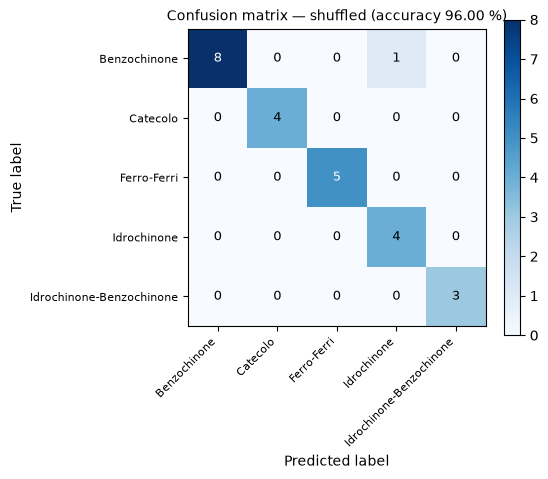

### concentrations_based split — accuracy 100.00 %

,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
Benzochinone,3,0,0,0,0
Catecolo,0,3,0,0,0
Ferro-Ferri,0,0,3,0,0
Idrochinone,0,0,0,3,0
Idrochinone-Benzochinone,0,0,0,0,3


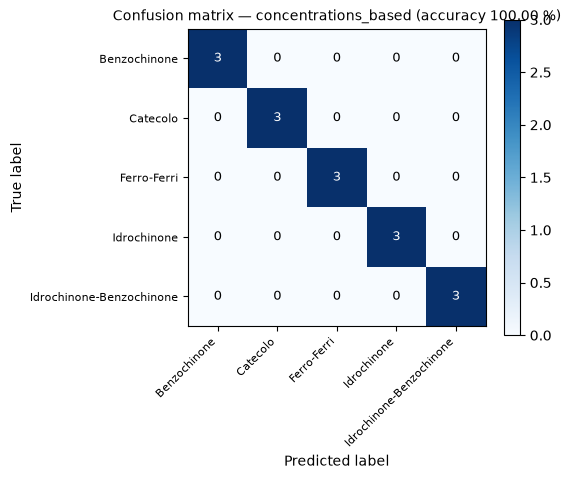

In [6]:
for s in run_summaries:
    cm = np.array(s["confusion_matrix"])

    display(Markdown(f"### {s['split']} split — accuracy {s['accuracy_percent']:.2f} %"))
    display(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))

    fig, ax = plt.subplots(figsize=(5.8, 4.9))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=8)
    ax.set_yticks(range(len(CLASSES)))
    ax.set_yticklabels(CLASSES, fontsize=8)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"Confusion matrix — {s['split']} (accuracy {s['accuracy_percent']:.2f} %)", fontsize=10)
    for i in range(len(CLASSES)):
        for j in range(len(CLASSES)):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=9,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    plt.show()

## 6. Classification reports

In [7]:
for s in run_summaries:
    display(Markdown(f"### {s['split']} split"))
    print((RESULTS_DIR / f"{s['split']}_classification_report.txt").read_text())

### shuffled split

CNN classification report - split: shuffled
model: CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
                          precision    recall  f1-score   support

            Benzochinone     1.0000    0.8889    0.9412         9
                Catecolo     1.0000    1.0000    1.0000         4
             Ferro-Ferri     1.0000    1.0000    1.0000         5
             Idrochinone     0.8000    1.0000    0.8889         4
Idrochinone-Benzochinone     1.0000    1.0000    1.0000         3

                accuracy                         0.9600        25
               macro avg     0.9600    0.9778    0.9660        25
            weighted avg     0.9680    0.9600    0.9610        25



### concentrations_based split

CNN classification report - split: concentrations_based
model: CNN_5classes__epo_4000_pat_1000_batch_16_tl.keras
                          precision    recall  f1-score   support

            Benzochinone     1.0000    1.0000    1.0000         3
                Catecolo     1.0000    1.0000    1.0000         3
             Ferro-Ferri     1.0000    1.0000    1.0000         3
             Idrochinone     1.0000    1.0000    1.0000         3
Idrochinone-Benzochinone     1.0000    1.0000    1.0000         3

                accuracy                         1.0000        15
               macro avg     1.0000    1.0000    1.0000        15
            weighted avg     1.0000    1.0000    1.0000        15



## 7. Per image predictions

In [8]:
def highlight_wrong(df):
    """Colour the wrongly classified rows red (falls back to a plain table)."""
    try:
        return df.style.apply(
            lambda row: ["background-color: #ffe3e3" if row["result"] == "WRONG" else "" for _ in row],
            axis=1,
        )
    except Exception:
        return df


predictions = {}
for s in run_summaries:
    raw = pd.read_csv(RESULTS_DIR / f"{s['split']}_predictions.csv")
    predictions[s["split"]] = raw

    show = pd.DataFrame({
        "#": range(len(raw)),
        "file": raw["file"],
        "true class": raw["true_class"],
        "predicted class": raw["predicted_class"],
        "confidence": raw["max_confidence"].round(4),
        "result": raw["correct"].astype(str).map({"True": "OK", "False": "WRONG"}),
    })

    display(Markdown(f"### {s['split']} split — {len(raw)} images"))
    display(highlight_wrong(show))

### shuffled split — 25 images

,#,file,true class,predicted class,confidence,result
0,0,0.01mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.697700,OK
1,1,0.01mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.901700,OK
2,2,0.1mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.922700,OK
3,3,0.5mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.791600,OK
4,4,1mMSPE-Benzochinone_1.png,Benzochinone,Benzochinone,0.716600,OK
5,5,1mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.962700,OK
6,6,2mMSPE-Benzochinone_1.png,Benzochinone,Idrochinone,0.598700,WRONG
7,7,2mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.954700,OK
8,8,2mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.957600,OK
9,9,0.01mMSPE-Catecolo_1.png,Catecolo,Catecolo,0.877900,OK


### concentrations_based split — 15 images

,#,file,true class,predicted class,confidence,result
0,0,1mMSPE-Benzochinone_1.png,Benzochinone,Benzochinone,0.716600,OK
1,1,1mMSPE-Benzochinone_2.png,Benzochinone,Benzochinone,0.914900,OK
2,2,1mMSPE-Benzochinone_3.png,Benzochinone,Benzochinone,0.962700,OK
3,3,1mMSPE-Catecolo_1.png,Catecolo,Catecolo,0.992900,OK
4,4,1mMSPE-Catecolo_2.png,Catecolo,Catecolo,0.991400,OK
5,5,1mMSPE-Catecolo_3.png,Catecolo,Catecolo,0.966500,OK
6,6,1mMSPE-Ferro-Ferri_1.png,Ferro-Ferri,Ferro-Ferri,0.995900,OK
7,7,1mMSPE-Ferro-Ferri_2.png,Ferro-Ferri,Ferro-Ferri,0.994700,OK
8,8,1mMSPE-Ferro-Ferri_3.png,Ferro-Ferri,Ferro-Ferri,0.994000,OK
9,9,1mMSPE-Idrochinone_1.png,Idrochinone,Idrochinone,0.998100,OK


## 8. Misclassified images

### 1 misclassified image(s) of 40

**2mMSPE-Benzochinone_1.png** — shuffled split  
true: `Benzochinone` &nbsp;&nbsp; predicted: `Idrochinone` &nbsp;&nbsp; confidence: **0.5987**

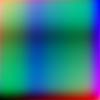

,probability
Benzochinone,0.2783
Catecolo,0.0781
Ferro-Ferri,0.0103
Idrochinone,0.5987
Idrochinone-Benzochinone,0.0345


In [9]:
wrong = pd.concat(
    [predictions[s["split"]].assign(split=s["split"]) for s in run_summaries], ignore_index=True
)
wrong = wrong[wrong["correct"].astype(str) == "False"]

if len(wrong) == 0:
    display(Markdown("### No misclassified images — every test image was classified correctly."))
else:
    display(Markdown(f"### {len(wrong)} misclassified image(s) of {tot_images}"))
    for _, r in wrong.iterrows():
        display(Markdown(
            f"**{r['file']}** — {r['split']} split  \n"
            f"true: `{r['true_class']}` &nbsp;&nbsp; predicted: `{r['predicted_class']}` "
            f"&nbsp;&nbsp; confidence: **{r['max_confidence']:.4f}**"))
        hits = glob.glob(str(DATA_DIR / r["split"] / "Test" / r["true_class"] / r["file"]))
        if hits:
            display(IPImage(filename=hits[0], width=190))
        probs = pd.DataFrame(
            {c: [round(float(r[f"prob_{c}"]), 4)] for c in CLASSES}, index=["probability"]
        ).T
        display(probs)

## 9. Appendix — full probability matrix

In [10]:
for s in run_summaries:
    raw = predictions[s["split"]]
    probs = raw[["file", "true_class"] + [f"prob_{c}" for c in CLASSES]].copy()
    probs.columns = ["file", "true"] + CLASSES
    display(Markdown(f"### {s['split']} split"))
    display(probs.round(4))

### shuffled split

,file,true,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
0,0.01mMSPE-Benzochinone_2.png,Benzochinone,0.6977,0.0514,0.0070,0.2191,0.0247
1,0.01mMSPE-Benzochinone_3.png,Benzochinone,0.9017,0.0249,0.0048,0.0514,0.0173
2,0.1mMSPE-Benzochinone_2.png,Benzochinone,0.9227,0.0284,0.0092,0.0312,0.0084
3,0.5mMSPE-Benzochinone_2.png,Benzochinone,0.7916,0.0577,0.0084,0.1355,0.0068
4,1mMSPE-Benzochinone_1.png,Benzochinone,0.7166,0.0166,0.0310,0.2285,0.0073
5,1mMSPE-Benzochinone_3.png,Benzochinone,0.9627,0.0113,0.0046,0.0118,0.0096
6,2mMSPE-Benzochinone_1.png,Benzochinone,0.2783,0.0781,0.0103,0.5987,0.0345
7,2mMSPE-Benzochinone_2.png,Benzochinone,0.9547,0.0142,0.0044,0.0075,0.0192
8,2mMSPE-Benzochinone_3.png,Benzochinone,0.9576,0.0144,0.0039,0.0072,0.0170
9,0.01mMSPE-Catecolo_1.png,Catecolo,0.0596,0.8779,0.0191,0.0366,0.0069


### concentrations_based split

,file,true,Benzochinone,Catecolo,Ferro-Ferri,Idrochinone,Idrochinone-Benzochinone
0,1mMSPE-Benzochinone_1.png,Benzochinone,0.7166,0.0166,0.0310,0.2285,0.0073
1,1mMSPE-Benzochinone_2.png,Benzochinone,0.9149,0.0564,0.0082,0.0101,0.0104
2,1mMSPE-Benzochinone_3.png,Benzochinone,0.9627,0.0113,0.0046,0.0118,0.0096
3,1mMSPE-Catecolo_1.png,Catecolo,0.0014,0.9929,0.0023,0.0010,0.0025
4,1mMSPE-Catecolo_2.png,Catecolo,0.0020,0.9914,0.0023,0.0013,0.0030
5,1mMSPE-Catecolo_3.png,Catecolo,0.0180,0.9665,0.0060,0.0034,0.0061
6,1mMSPE-Ferro-Ferri_1.png,Ferro-Ferri,0.0002,0.0003,0.9959,0.0035,0.0001
7,1mMSPE-Ferro-Ferri_2.png,Ferro-Ferri,0.0003,0.0005,0.9947,0.0044,0.0001
8,1mMSPE-Ferro-Ferri_3.png,Ferro-Ferri,0.0005,0.0006,0.9940,0.0047,0.0001
9,1mMSPE-Idrochinone_1.png,Idrochinone,0.0003,0.0006,0.0003,0.9981,0.0007


## 10. Final report files and download

The next cells build the final report in three formats (PDF / Word / text) together with the
single complete output file, pack every result into `results/CNN_Results_Package.zip`, and
show the download links.

| File | What it is |
|---|---|
| `CNN_Final_Report.pdf` | final report, A4, ready to print or share |
| `CNN_Final_Report.docx` | same report, editable in Word |
| `CNN_Final_Report.txt` | same report as plain text |
| `CNN_COMPLETE_OUTPUT.txt` | everything the CNN produced, in one file |
| `CNN_FULL_REPORT.html` | self contained HTML report |
| `CNN_Results_Package.zip` | all of the above + this notebook

In [11]:
# --- 10a. build the final report files (PDF / Word / text) -----------------
sys.argv = ["make_full_report.py", "--results_dir", str(RESULTS_DIR), "--data_dir", str(DATA_DIR)]
full_report.main()

sys.argv = ["make_final_report.py", "--results_dir", str(RESULTS_DIR),
            "--data_dir", str(DATA_DIR), "--model", str(MODEL_PATH)]
final_report.main()

# --- 10b. package everything into one ZIP ----------------------------------
ZIP_PATH = RESULTS_DIR / "CNN_Results_Package.zip"
EXTENSIONS = {".pdf", ".docx", ".txt", ".csv", ".png", ".json", ".html"}

with zipfile.ZipFile(ZIP_PATH, "w", zipfile.ZIP_DEFLATED) as z:
    for p in sorted(RESULTS_DIR.iterdir()):
        if p.is_file() and p != ZIP_PATH and p.suffix.lower() in EXTENSIONS:
            z.write(p, arcname=p.name)
    notebook = Path("GAF_CNN_Final_Report.ipynb")
    if notebook.exists():
        z.write(notebook, arcname=notebook.name)

print("ZIP package:", ZIP_PATH, f"({ZIP_PATH.stat().st_size:,} bytes)")

Wrote:
  /home/user/CHEM_GAF_CNN/results/CNN_COMPLETE_OUTPUT.txt  (56,478 bytes)
  /home/user/CHEM_GAF_CNN/results/CNN_FULL_REPORT.html  (350,481 bytes)
  /home/user/CHEM_GAF_CNN/results/all_generated_images_manifest.csv  (47,093 bytes)
  /home/user/CHEM_GAF_CNN/results/README.md  (2,893 bytes)


  /home/user/CHEM_GAF_CNN/results/CNN_Final_Report.pdf  (207,870 bytes)
  /home/user/CHEM_GAF_CNN/results/CNN_Final_Report.docx  (150,652 bytes)
  /home/user/CHEM_GAF_CNN/results/CNN_Final_Report.txt  (16,730 bytes)
ZIP package: /home/user/CHEM_GAF_CNN/results/CNN_Results_Package.zip (700,224 bytes)


In [12]:
# --- 10c. download links ---------------------------------------------------
display(Markdown("### Download"))

downloads = [
    ("Final report — PDF",             RESULTS_DIR / "CNN_Final_Report.pdf"),
    ("Final report — Word",            RESULTS_DIR / "CNN_Final_Report.docx"),
    ("Final report — text",            RESULTS_DIR / "CNN_Final_Report.txt"),
    ("Complete output (one file)",     RESULTS_DIR / "CNN_COMPLETE_OUTPUT.txt"),
    ("HTML report",                    RESULTS_DIR / "CNN_FULL_REPORT.html"),
    ("Per image predictions (CSV)",    RESULTS_DIR / "shuffled_predictions.csv"),
    ("Confusion matrix image",         RESULTS_DIR / "shuffled_confusion_matrix.png"),
    ("All results — ZIP",              RESULTS_DIR / "CNN_Results_Package.zip"),
    ("This notebook",                  Path("GAF_CNN_Final_Report.ipynb")),
]

for label, path in downloads:
    if path.exists():
        display(FileLink(str(path), result_html_prefix=f"{label}: "))
    else:
        print(f"{label}: {path}  (not found)")

### Download

/home/user/CHEM_GAF_CNN/results/CNN_Final_Report.pdf

/home/user/CHEM_GAF_CNN/results/CNN_Final_Report.docx

/home/user/CHEM_GAF_CNN/results/CNN_Final_Report.txt

/home/user/CHEM_GAF_CNN/results/CNN_COMPLETE_OUTPUT.txt

/home/user/CHEM_GAF_CNN/results/CNN_FULL_REPORT.html

/home/user/CHEM_GAF_CNN/results/shuffled_predictions.csv

/home/user/CHEM_GAF_CNN/results/shuffled_confusion_matrix.png

/home/user/CHEM_GAF_CNN/results/CNN_Results_Package.zip

/home/user/CHEM_GAF_CNN/GAF_CNN_Final_Report.ipynb

---
### Summary of the final result

| Test set | Images | Correct | Accuracy |
|---|---|---|---|
| `shuffled` | 25 | 24 | **96.00 %** |
| `concentrations_based` | 15 | 15 | **100.00 %** |
| **Combined** | **40** | **39** | **97.50 %** |

* The `concentrations_based` set contains every concentration (0.01, 0.1, 0.5, 1, 2 mM) and is classified perfectly:
  the GAF representation preserves the information needed to recognise the substance independently of concentration.
* The single error is a Benzochinone image at 2 mM predicted as Idrochinone (confidence 0.60) — the two molecules
  have very similar quinone / hydroquinone redox responses.
* Reports: `results/CNN_Final_Report.pdf`, `.docx`, `.txt` — plus `results/CNN_COMPLETE_OUTPUT.txt` for the raw data.

*Generated by the GAF-CNN pipeline (java GAF image generator + python CNN classifier).*
